In [ ]:
import torch
import matplotlib.pyplot as plt

torch.manual_seed(42)

In [6]:
# 单头注意力
seq_len = 4
d_k = 8
d_v = 8

Q = torch.randn(4, 8)
K = torch.randn(4, 8)
V = torch.randn(4, 8)

# S.shape=(4, 4),A.shape=(4, 4)
S = Q @ K.T / d_k**0.5
A = torch.softmax(S, dim=1)

# O.shape=(4, 8)
O = A @ V

print("Attention Scores:\n", S)
print("\nAttention Weights:\n", A)

Attention Scores:
 tensor([[-1.4870, -1.7335,  1.2169, -1.4836],
        [ 0.5272,  0.0920,  0.5617, -0.2376],
        [-0.8825,  0.1001,  0.5507, -0.1795],
        [ 0.0992,  0.0586,  0.4615, -0.7039]])

Attention Weights:
 tensor([[0.0564, 0.0441, 0.8429, 0.0566],
        [0.3177, 0.2056, 0.3289, 0.1479],
        [0.1012, 0.2703, 0.4242, 0.2044],
        [0.2601, 0.2497, 0.3737, 0.1165]])


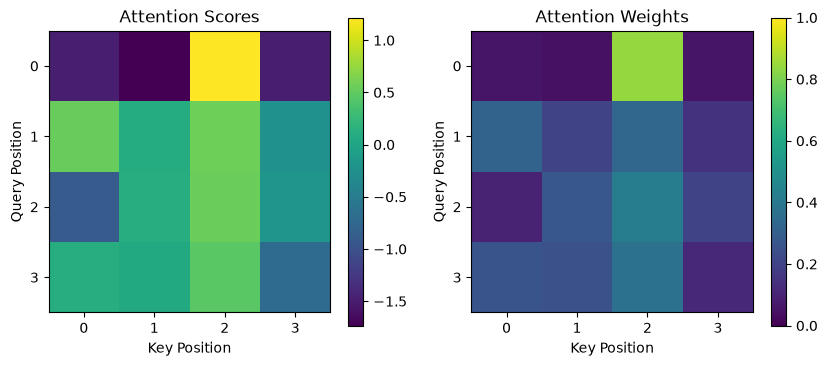

In [8]:
# 热力图
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

im1 = axes[0].imshow(S, cmap="viridis")
axes[0].set_title("Attention Scores")
fig.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(A, cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Attention Weights")
fig.colorbar(im2, ax=axes[1])

for ax in axes:
    ax.set_xlabel("Key Position")
    ax.set_ylabel("Query Position")
    ax.set_xticks(range(seq_len))
    ax.set_yticks(range(seq_len))

plt.show()

In [9]:
# 多头注意力
seq_len = 4
d_model = 8
num_heads = 2
d_k = d_model // num_heads
d_v = d_model // num_heads

X = torch.randn(seq_len, d_model)
Wq1 = torch.randn(d_k, d_model) / d_model**0.5
Wk1 = torch.randn(d_k, d_model) / d_model**0.5
Wv1 = torch.randn(d_v, d_model) / d_model**0.5
Wq2 = torch.randn(d_k, d_model) / d_model**0.5
Wk2 = torch.randn(d_k, d_model) / d_model**0.5
Wv2 = torch.randn(d_v, d_model) / d_model**0.5

Q1 = X @ Wq1.T
K1 = X @ Wk1.T
V1 = X @ Wv1.T
Q2 = X @ Wq2.T
K2 = X @ Wk2.T
V2 = X @ Wv2.T

S1 = Q1 @ K1.T / d_k**0.5
A1 = torch.softmax(S1, dim=1)
O1 = A1 @ V1
S2 = Q2 @ K2.T / d_k**0.5
A2 = torch.softmax(S2, dim=1)
O2 = A2 @ V2

O_concat = torch.cat([O1, O2], dim=1)
Wo = torch.randn(d_model, d_model) / d_model**0.5
O = O_concat @ Wo.T

print("\nHead 1 Scores:\n", S1)
print("\nHead 1 Weights:\n", A1)
print("\nHead 2 Scores:\n", S2)
print("\nHead 2 Weights:\n", A2)


Head 1 Scores:
 tensor([[ 0.1952,  1.8215, -0.7782,  0.7828],
        [-0.0925,  1.0305,  0.0704,  0.4586],
        [ 0.2755, -2.7080,  0.2890, -2.4994],
        [-1.7690,  0.8318,  0.6847,  2.0341]])

Head 1 Weights:
 tensor([[0.1210, 0.6154, 0.0457, 0.2178],
        [0.1431, 0.4400, 0.1685, 0.2484],
        [0.4702, 0.0238, 0.4766, 0.0293],
        [0.0141, 0.1899, 0.1640, 0.6320]])

Head 2 Scores:
 tensor([[-0.3743, -0.0533, -0.4311, -0.1287],
        [ 1.0481,  0.6381, -1.1271,  0.6456],
        [ 0.0951,  0.5944, -0.4534,  0.1931],
        [ 0.1544,  0.0200,  1.0655, -0.1239]])

Head 2 Weights:
 tensor([[0.2173, 0.2996, 0.2053, 0.2778],
        [0.4089, 0.2713, 0.0464, 0.2734],
        [0.2310, 0.3807, 0.1335, 0.2548],
        [0.1954, 0.1708, 0.4859, 0.1479]])


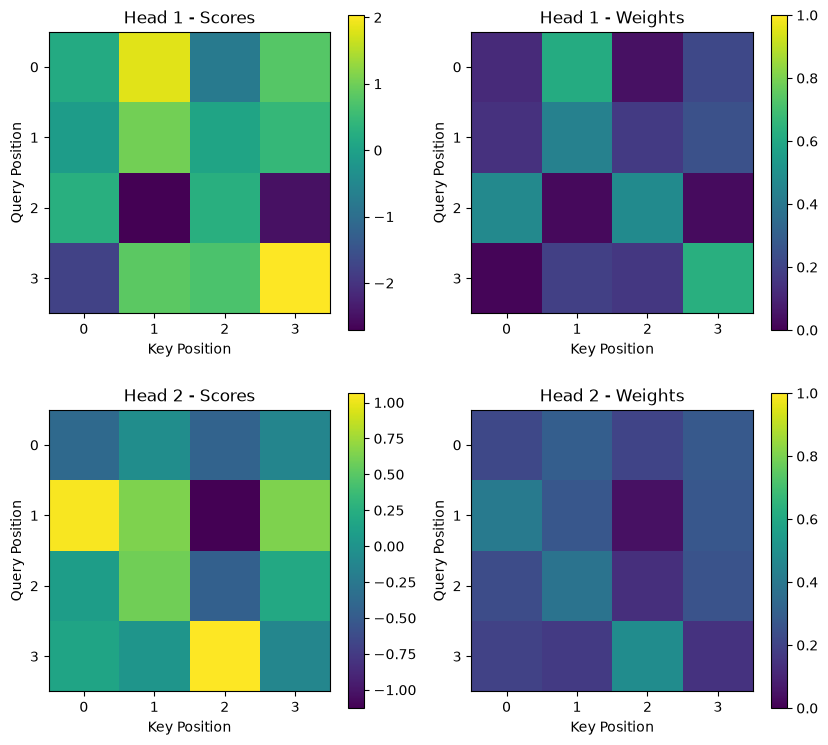

In [11]:
# 多头注意力热力图
fig, axes = plt.subplots(2, 2, figsize=(10, 9))

scores = [S1, S2]
weights = [A1, A2]

for i in range(num_heads):

    im1 = axes[i, 0].imshow(
        scores[i],
        cmap="viridis"
    )

    axes[i, 0].set_title(f"Head {i + 1} - Scores")
    fig.colorbar(im1, ax=axes[i, 0])

    im2 = axes[i, 1].imshow(
        weights[i],
        cmap="viridis",
        vmin=0,
        vmax=1
    )

    axes[i, 1].set_title(f"Head {i + 1} - Weights")
    fig.colorbar(im2, ax=axes[i, 1])

for ax in axes.flat:
    ax.set_xlabel("Key Position")
    ax.set_ylabel("Query Position")
    ax.set_xticks(range(seq_len))
    ax.set_yticks(range(seq_len))

plt.show()